<img src="images/mcdc.png" alt="Metropolitan Chicago Data Science Corps logo" style="width:150px; margin:18px 0;">

## About This Lesson

Suppose a model predicts root exudation from root measurements. Do we want to predict another observation from a familiar species, or an observation from a species absent from training? Those questions require different evaluations.

We use the public Morton Arboretum-affiliated dataset explored in the companion PCA lesson. Root exudation concerns materials released by roots into their surroundings. Here we predict the archived mass-specific exudation variable, `er_mass`, from six traits. Species names define validation groups and never enter the model as predictors.

The [Dryad dataset](https://doi.org/10.5061/dryad.vmcvdnd78) accompanies research by Oh and colleagues conducted at Morton. It is a separate research dataset from the inventory described in [MCDC's Morton data-cleaning project](https://sites.northwestern.edu/mcdc/data-cleaning-morton-arboretum-tree-species/). This lesson connects MCDC's emphasis on responsible data use to the question of whether an analysis transfers to new observations. It is not a reproduction of the paper's models or a validated decision tool.

## Learning objectives

By the end of the lesson, you should be able to:

1. Define a prediction target and a realistic generalization question.
2. Distinguish random row splits from species-held-out splits.
3. Fit a baseline and a regularized linear model.
4. Keep scaling inside training folds with a pipeline.
5. Generate and audit out-of-fold predictions.
6. Compare observation-weighted and species-weighted errors.
7. Explain why changing the split changes what performance means.
8. Report small-sample findings without implying causation or deployment readiness.

**Prerequisites:** pandas, basic regression, feature scaling, and error metrics. The PCA lesson is helpful but not required. We start from the original workbook, not its globally scaled PCA outputs.

**Suggested duration:** Two 75-minute sessions, with exercises as homework. Parts 1–5 introduce the data and evaluation design; Parts 6–10 calculate and interpret results.

## Setup

Run cells in order from the summer MCDC folder. The original data live under `data/raw/morton_root_traits/`. This lesson writes only its own derived results under `data/processed/morton_grouped_cv/`.

In [1]:
# Uncomment only if your notebook environment lacks these packages.
# %pip install pandas numpy openpyxl matplotlib scikit-learn requests

In [2]:
from pathlib import Path
import hashlib
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_dir = Path("data/raw/morton_root_traits")
out_dir = Path("data/processed/morton_grouped_cv")
out_dir.mkdir(parents=True, exist_ok=True)
data_path = raw_dir / "final_exudate_data_submission.xlsx"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Source, acquisition, and prediction question

**Source citation:** Oh, Young Eui; Midgley, Meghan; McCormack, Luke et al. (2026). *Data from: Plant functional groups and root traits are linked to exudation rates of mature temperate trees*. Dryad. https://doi.org/10.5061/dryad.vmcvdnd78

- Release used: May 6, 2026, Dryad API version 3.
- Original file: `final_exudate_data_submission.xlsx`; 23,521 bytes; CC0 1.0.
- [Download page and data dictionary](https://doi.org/10.5061/dryad.vmcvdnd78).
- [Related article](https://doi.org/10.1111/1365-2435.70363).

The original workbook was downloaded manually from Dryad and supplied for these lessons on September 5, 2026 after automated access failed. It is bundled unchanged and its checksum matches [Dryad's file metadata](https://datadryad.org/api/v2/files/4747058). To obtain it again, open the DOI, select its filename under **Data files**, and save it in the raw-data folder. The next cell also attempts downloading if absent. If the request fails, use the manual route. Existing local data allow offline execution.

**Our question:** How well can a fixed prediction procedure estimate archived `er_mass` values for held-out observations when their species is absent from training?

The dictionary labels `er_mass` as a mass-specific exudation rate. The archive contains inconsistent physical-unit descriptions, including for some root traits. We preserve all values and report errors in **archived `er_mass` units**. Resolve physical units before interpreting absolute ecological magnitudes. Positive rescaling of an entire predictor cancels after standardization; scaling cannot repair mixed units within a column.

In [3]:
DATASET_DOI = "https://doi.org/10.5061/dryad.vmcvdnd78"
DOWNLOAD_URL = "https://datadryad.org/downloads/file_stream/4747058"
EXPECTED_SHA256 = "f7ba355a9480893e9d25f83cf7ef209e4cfba1547419dcef1931187a4b313df4"
if not data_path.exists():
    response = requests.get(DOWNLOAD_URL, timeout=60)
    response.raise_for_status()
    payload = response.content
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Download differs from the documented workbook. Inspect the source.")
    raw_dir.mkdir(parents=True, exist_ok=True)
    data_path.write_bytes(payload)
source_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_hash == EXPECTED_SHA256, "Unexpected source workbook version."
df = pd.read_excel(data_path, sheet_name="final_exudate_data_stat", engine="openpyxl")
df.index.name = "source_row_index"
print("Verified workbook shape:", df.shape)
display(df.head())

Verified workbook shape: (60, 23)


,tree_ID,species,species_scientific,myco,phylo,leaf,Combined,Combi_leaf_phylo,Family,er_mass,...,sra,%N,%C,C:N,branching_intensity,total_exudate_μg_day,N_uptake,NH4_uptake,NO3_uptake,mass_g
source_row_index,,,,,,,,,,,,,,,,,,,,,
0,b. cypress_1,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,749.140624,...,301.789784,2.003366,48.201004,24.060006,1.797463,38.131258,1101.70200,658.222576,443.479626,0.0509
1,b. cypress_2,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,546.803153,...,254.632076,1.554716,47.825893,30.761818,1.750861,11.592227,-681.05200,-337.670959,-343.381181,0.0212
2,b. cypress_3,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,367.718883,...,238.855895,1.831549,46.995659,25.658973,2.639587,33.683050,540.89800,298.889792,242.007967,0.0916
3,b. cypress_4,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,643.996712,...,260.977337,2.169584,44.773678,20.636988,1.909334,22.733084,577.47000,448.700203,128.770175,0.0353
4,hemlock_1,T.canadensis,Tsuga canadensis,EcM,Gymnosperm,Evergreen,EcM.Gymnosperm,ev_gymno,Pinaceae,1776.793149,...,146.810370,1.503732,48.279308,32.106334,5.031565,599.667688,453.40054,291.964764,161.435776,0.3375


## Part 2 — Separate predictors, target, and groups

The six predictors describe root diameter, specific root length (`srl`), tissue density (`rtd`), specific root area (`sra`), nitrogen concentration (`%N`), and branching intensity. We deliberately use the same trait set as the PCA lesson.

`y` is the value we want to predict. `groups` describes which observations share a species. `tree_ID` and source indexes identify records; they are not measurements. We exclude exudation-derived quantities and related totals from `X`, because information derived from the outcome could make the prediction task circular. Predictor availability must also match the intended future use.

We keep complete finite observations and document exclusions. If observations repeat across the same individual, the split design must also respect that dependence. The supplied release has unique tree IDs.

In [4]:
features = ["diameter", "srl", "rtd", "sra", "%N", "branching_intensity"]
target = "er_mass"
numeric = df[features + [target]].apply(pd.to_numeric, errors="coerce")
introduced_missing = numeric.isna() & df[features + [target]].notna()
assert not introduced_missing.any().any(), "Inspect nonnumeric values before analysis."
keep = np.isfinite(numeric.to_numpy(dtype=float)).all(axis=1) & df["species"].notna()
X = numeric.loc[keep, features].copy()
y = numeric.loc[keep, target].copy()
groups = df.loc[keep, "species"].astype(str)
ids = df.loc[keep, "tree_ID"].copy()
assert ids.notna().all() and ids.is_unique, "Reconsider grouping for missing or repeated tree IDs."
assert X.index.equals(y.index) and X.index.equals(groups.index)
print(f"Retained {len(X)} of {len(df)} rows from {groups.nunique()} species.")
display(pd.DataFrame({"species": groups, "target": y}).groupby("species").agg(
    n=("target", "size"), median=("target", "median"), minimum=("target", "min"), maximum=("target", "max")))

Retained 60 of 60 rows from 11 species.


,n,median,minimum,maximum
species,,,,
A.saccharum,5,469.398626,83.119797,2177.012101
A.triloba,4,367.251323,156.946799,1520.099738
C.ovata,5,187.925929,149.134512,1744.871332
C.pisifera,7,344.949249,86.808809,1893.142743
J.chinensis,6,483.472268,192.160983,4780.757465
L.gmelinii,6,3272.646816,1104.762242,8383.939220
P.abies,6,1635.323036,664.308546,2196.343273
P.occidentalis,5,1129.311367,263.113700,2530.760054
Q.bicolor,6,614.981972,146.160911,1429.538218


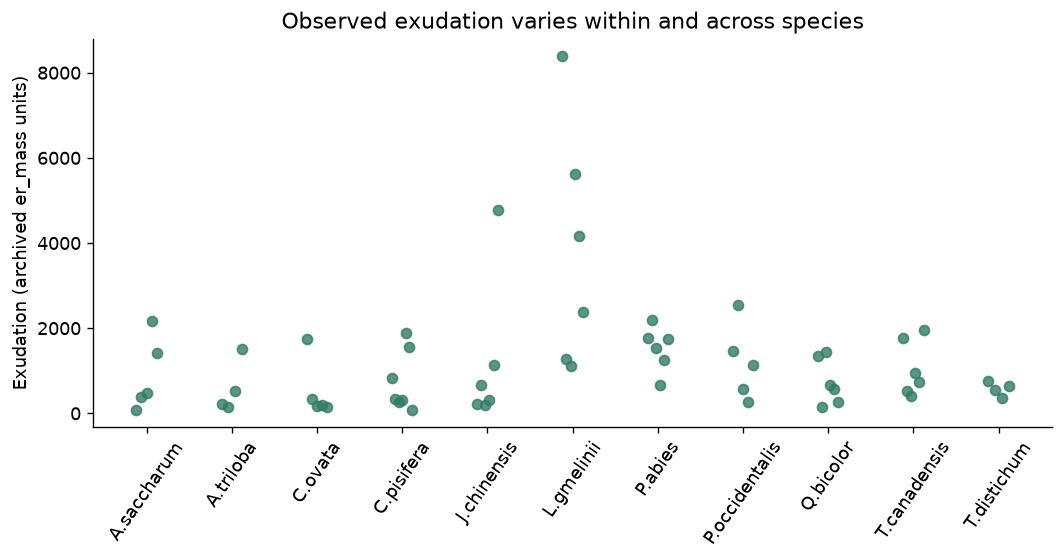

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
species_order = sorted(groups.unique())
for i, species in enumerate(species_order):
    values = y.loc[groups == species].to_numpy()
    offsets = np.linspace(-.12, .12, len(values))
    ax.scatter(np.full(len(values), i) + offsets, values, color="#327b65", alpha=.8)
ax.set(xticks=range(len(species_order)), xticklabels=species_order,
       ylabel="Exudation (archived er_mass units)", title="Observed exudation varies within and across species")
ax.tick_params(axis="x", rotation=55)
fig.tight_layout()
plt.show()

### Check your understanding

Would a random train/test split ensure that test species are new? Why might differences across species matter even when species names are excluded from the predictors?

The target plot describes the sample. We do not remove large values just because they make modeling difficult. Data checks are distinct from choosing a model that performs well on a selected subset.

## Part 3 — Define two evaluation designs

**Shuffled row cross-validation:** Randomly divide observations into folds. A test row may share its species with training rows. This addresses additional observations from this mixture of species more closely than it addresses new species.

**Leave-one-species-out cross-validation:** Hold out all observations from one species, train on the others, and repeat for every species. Every observation receives a prediction from a model that has never trained on its species.

We use 11 folds in both designs to keep training sizes roughly similar. Fold sizes still differ because species counts differ. Random row splitting is not automatically an error; it answers a different question. For a new-species claim, shared species can produce an overly favorable assessment, but the actual direction and size of the difference must be measured.

In [6]:
SEED = 42
n_species = groups.nunique()
random_splits = list(KFold(n_splits=n_species, shuffle=True, random_state=SEED).split(X))
species_splits = list(LeaveOneGroupOut().split(X, y, groups))
split_sets = {"Shuffled rows": random_splits, "Held-out species": species_splits}

def audit_splits(splits, require_new_species=False):
    rows = []
    test_counts = np.zeros(len(X), dtype=int)
    for fold, (train, test) in enumerate(splits, start=1):
        assert not set(train) & set(test)
        assert len(train) + len(test) == len(X)
        overlap = set(groups.iloc[train]) & set(groups.iloc[test])
        if require_new_species:
            assert not overlap
        test_counts[test] += 1
        rows.append({"fold": fold, "n_train": len(train), "n_test": len(test),
                     "shared_species": len(overlap),
                     "test_species": ", ".join(sorted(set(groups.iloc[test])))})
    assert np.all(test_counts == 1), "Every observation must be tested exactly once."
    return pd.DataFrame(rows)

split_audits = {name: audit_splits(splits, name == "Held-out species")
                for name, splits in split_sets.items()}
display(pd.concat(split_audits, names=["design", "row"]))

fold  n_train  n_test  shared_species  \
design           row                                          
Shuffled rows    0       1       54       6               6   
                 1       2       54       6               5   
                 2       3       54       6               5   
                 3       4       54       6               6   
                 4       5       54       6               5   
                 5       6       55       5               4   
                 6       7       55       5               4   
                 7       8       55       5               3   
                 8       9       55       5               5   
                 9      10       55       5               4   
                 10     11       55       5               4   
Held-out species 0       1       55       5               0   
                 1       2       56       4               0   
                 2       3       55       5               0   
                 3       4       53       7               0   
                 4       5       54       6               0   
                 5       6       54       6               0   
                 6       7       54       6               0   
                 7       8       55       5               0   
                 8       9       54       6               0   
                 9      10       54       6               0   
                 10     11       56       4               0   

                                                           test_species  
design           row                                                     
Shuffled rows    0    C.ovata, C.pisifera, P.abies, Q.bicolor, T.can...  
                 1    A.triloba, C.ovata, P.abies, P.occidentalis, Q...  
                 2    A.saccharum, J.chinensis, Q.bicolor, T.canaden...  
                 3    A.triloba, C.pisifera, J.chinensis, P.abies, P...  
                 4    A.saccharum, J.chinensis, L.gmelinii, P.occide...  
                 5     C.ovata, J.chinensis, L.gmelinii, P.occidentalis  
                 6        A.saccharum, A.triloba, C.pisifera, Q.bicolor  
                 7                     L.gmelinii, P.abies, T.distichum  
                 8    A.triloba, C.ovata, C.pisifera, L.gmelinii, Q....  
                 9    J.chinensis, L.gmelinii, P.occidentalis, T.can...  
                 10         A.saccharum, C.ovata, C.pisifera, Q.bicolor  
Held-out species 0                                          A.saccharum  
                 1                                            A.triloba  
                 2                                              C.ovata  
                 3                                           C.pisifera  
                 4                                          J.chinensis  
                 5                                           L.gmelinii  
                 6                                              P.abies  
                 7                                       P.occidentalis  
                 8                                            Q.bicolor  
                 9                                         T.canadensis  
                 10                                         T.distichum

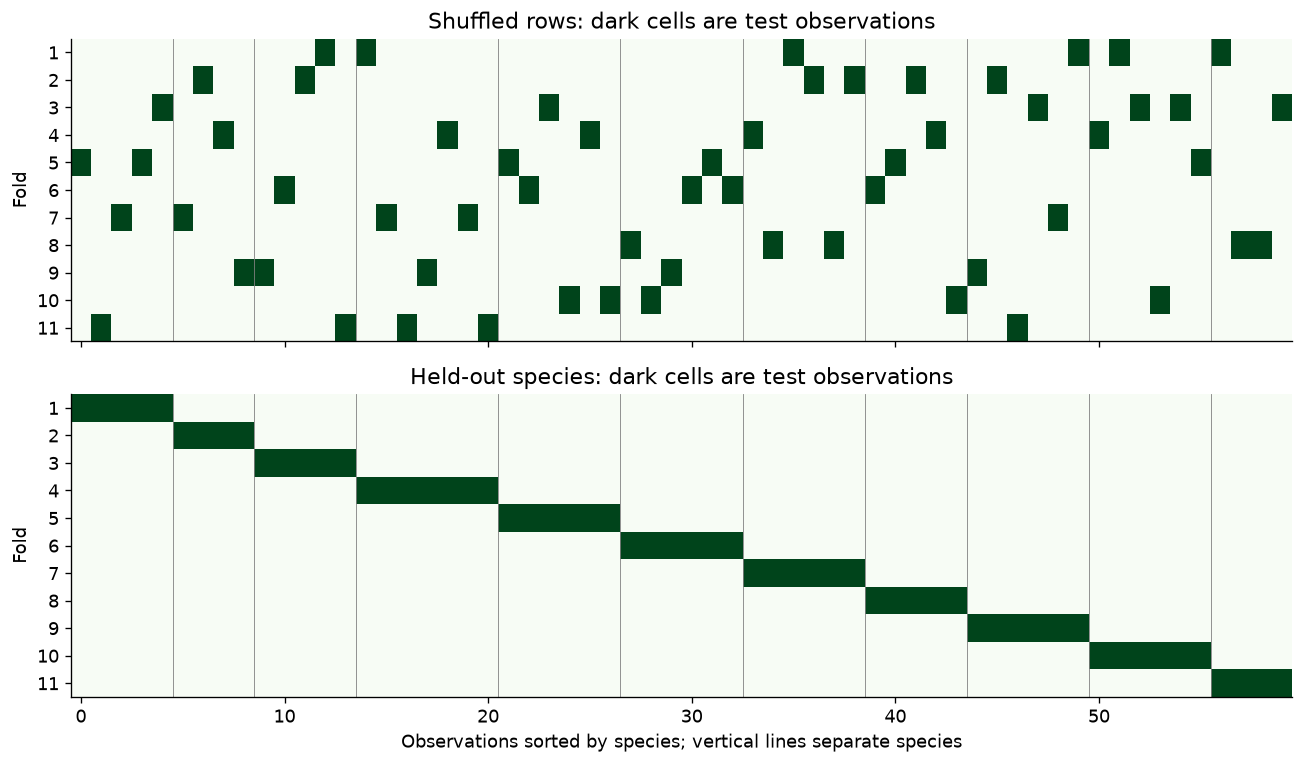

In [7]:
order = np.argsort(groups.to_numpy(), kind="stable")
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, (name, splits) in zip(axes, split_sets.items()):
    membership = np.zeros((len(splits), len(X)))
    for i, (_, test) in enumerate(splits):
        membership[i, test] = 1
    ax.imshow(membership[:, order], aspect="auto", interpolation="nearest", cmap="Greens", vmin=0, vmax=1)
    ax.set(ylabel="Fold", title=f"{name}: dark cells are test observations",
           yticks=range(len(splits)), yticklabels=range(1, len(splits)+1))
    boundaries = np.flatnonzero(groups.to_numpy()[order][1:] != groups.to_numpy()[order][:-1]) + .5
    for boundary in boundaries:
        ax.axvline(boundary, color="gray", linewidth=.5)
axes[-1].set_xlabel("Observations sorted by species; vertical lines separate species")
fig.tight_layout()
plt.show()

## Part 4 — Choose a baseline and a fixed model

A useful baseline predicts the **training-set median** for every test observation. It ignores the features but provides a reference for mean absolute error (MAE).

Ridge regression predicts a weighted sum of features plus an intercept. It penalizes large squared coefficients, which can help when predictors are correlated. We standardize inside its pipeline so differently scaled features are treated comparably by the penalty.

We choose `alpha=10` as a fixed teaching setting before comparing scores. It is not a tuned optimum. A larger alpha increases shrinkage. In this lesson we hold the model constant to investigate evaluation design. We do not choose an alpha, transform, or feature set using the held-out errors and then claim those same errors provide an independent final assessment.

In [8]:
ALPHA = 10.0
models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Scaled ridge": make_pipeline(StandardScaler(), Ridge(alpha=ALPHA, solver="svd")),
}
models["Scaled ridge"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10.0
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).

## Part 5 — Work through one held-out species

Each fold starts with a new copy of the model. Fitting the pipeline learns feature means and scales only from training rows. The test rows are transformed using those fitted parameters. Their target values are used only after prediction to calculate errors.

Do not load the globally standardized values or PCA scores from the earlier exploratory lesson. Those transformations were fitted on all observations. If PCA is added to a predictive workflow, it belongs inside this fold-specific pipeline too.

In [9]:
train, test = species_splits[0]
example = clone(models["Scaled ridge"])
example.fit(X.iloc[train], y.iloc[train])
prediction = example.predict(X.iloc[test])
assert set(groups.iloc[train]).isdisjoint(set(groups.iloc[test]))
np.testing.assert_allclose(example.named_steps["standardscaler"].mean_, X.iloc[train].mean())
print("Held-out species:", groups.iloc[test].unique().tolist())
display(pd.DataFrame({"observed": y.iloc[test], "predicted": prediction,
                      "absolute_error": np.abs(y.iloc[test] - prediction)}))
print("Fold MAE:", mean_absolute_error(y.iloc[test], prediction))

Held-out species: ['A.saccharum']


,observed,predicted,absolute_error
source_row_index,,,
27,83.119797,502.508725,419.388928
28,378.615304,660.575924,281.960619
29,469.398626,1084.889155,615.490529
30,2177.012101,787.601144,1389.410957
31,1418.018523,1143.166984,274.851539


Fold MAE: 596.2205144425469


## Part 6 — Collect out-of-fold predictions

An **out-of-fold prediction** comes from a fit that excluded that observation. In the grouped design, it also excluded every observation from the same species. The loop below stores row-level predictions and fold assignments so the evaluation can be audited.

MAE is the average absolute error and has the same units as the target. RMSE takes the square root of average squared error and gives more weight to large errors. We use both on the original archived target scale. These are not percentages, and a low error has meaning only relative to the target and a useful baseline.

In [10]:
def evaluate_oof(model, splits):
    predictions = np.full(len(X), np.nan)
    fold_ids = np.full(len(X), -1, dtype=int)
    for fold, (train, test) in enumerate(splits, start=1):
        fitted = clone(model)
        fitted.fit(X.iloc[train], y.iloc[train])
        predictions[test] = fitted.predict(X.iloc[test])
        fold_ids[test] = fold
        if hasattr(fitted, "named_steps"):
            np.testing.assert_allclose(fitted.named_steps["standardscaler"].mean_, X.iloc[train].mean())
    assert np.isfinite(predictions).all() and (fold_ids > 0).all()
    return pd.DataFrame({"tree_ID": ids, "species": groups, "fold": fold_ids,
                         "observed": y, "predicted": predictions,
                         "absolute_error": np.abs(y.to_numpy() - predictions)}, index=X.index)

prediction_tables = []
for design, splits in split_sets.items():
    for model_name, model in models.items():
        result = evaluate_oof(model, splits)
        result["design"] = design
        result["model"] = model_name
        prediction_tables.append(result)
oof = pd.concat(prediction_tables)
display(oof.head())
assert len(oof) == len(X) * len(split_sets) * len(models)

,tree_ID,species,fold,observed,predicted,absolute_error,design,model
source_row_index,,,,,,,,
0,b. cypress_1,T.distichum,1,749.140624,694.362309,54.778315,Shuffled rows,Median baseline
1,b. cypress_2,T.distichum,8,546.803153,664.708390,117.905238,Shuffled rows,Median baseline
2,b. cypress_3,T.distichum,8,367.718883,664.708390,296.989508,Shuffled rows,Median baseline
3,b. cypress_4,T.distichum,3,643.996712,789.048941,145.052228,Shuffled rows,Median baseline
4,hemlock_1,T.canadensis,4,1776.793149,664.508468,1112.284681,Shuffled rows,Median baseline


### Two ways of weighting errors

**Pooled MAE** gives each observation equal weight. **Macro species MAE** calculates MAE separately for each species and then averages the 11 results, giving each species equal weight. These quantities differ when species have different sample sizes or errors.

The pooled out-of-fold R² below compares total squared prediction error with variation around the full observed target mean. A negative value is possible. It is not the average of per-fold R², and it is not a direct comparison with our training-median baseline. Tiny within-species test sets can make fold-level R² particularly unstable, so we focus on errors and baseline comparisons.

,design,model,pooled_MAE,pooled_RMSE,macro_species_MAE,pooled_OOF_R2
0,Shuffled rows,Median baseline,886.973,1542.759,849.613,-0.154
1,Shuffled rows,Scaled ridge,952.872,1448.600,940.469,-0.017
2,Held-out species,Median baseline,884.001,1540.713,847.691,-0.151
3,Held-out species,Scaled ridge,1043.402,1604.969,1048.399,-0.249


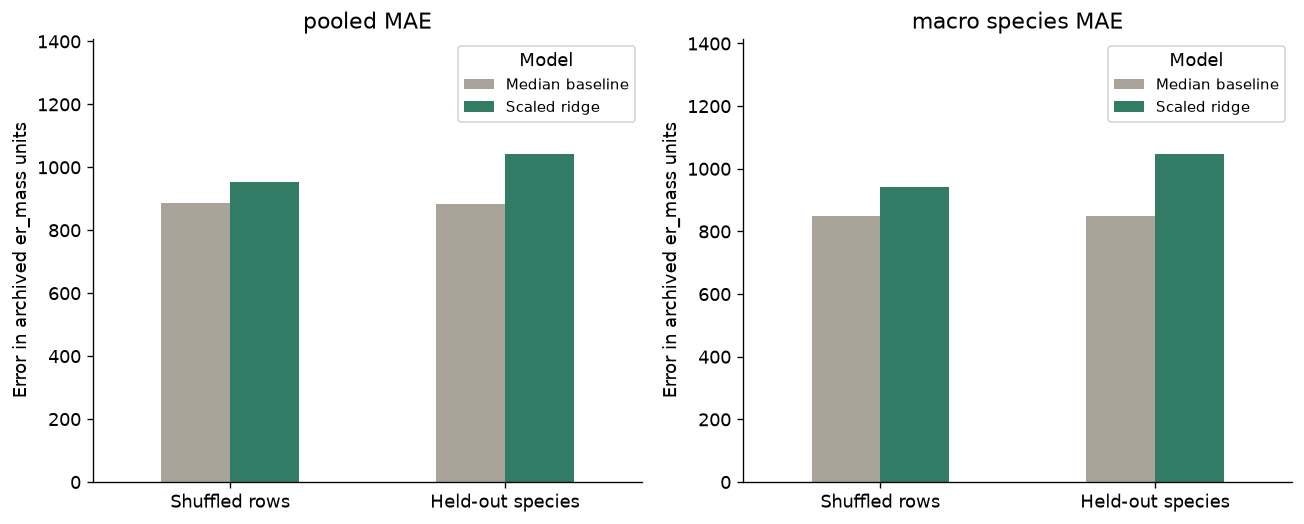

In [11]:
summary_rows = []
for (design, model_name), table in oof.groupby(["design", "model"], sort=False):
    summary_rows.append({"design": design, "model": model_name,
        "pooled_MAE": mean_absolute_error(table.observed, table.predicted),
        "pooled_RMSE": np.sqrt(mean_squared_error(table.observed, table.predicted)),
        "macro_species_MAE": table.groupby("species").absolute_error.mean().mean(),
        "pooled_OOF_R2": r2_score(table.observed, table.predicted)})
summary = pd.DataFrame(summary_rows)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ["pooled_MAE", "macro_species_MAE"]):
    summary.pivot(index="design", columns="model", values=metric).reindex(list(split_sets)).plot.bar(
        ax=ax, color=["#aaa39a", "#327b65"], rot=0)
    ax.set(title=metric.replace("_", " "), xlabel="", ylabel="Error in archived er_mass units")
    ax.set_ylim(0, summary[metric].max() * 1.35)
    ax.legend(title="Model", fontsize=9)
fig.tight_layout()
plt.show()

## Part 7 — Inspect predictions, not just a score

The diagonal in an observed-versus-predicted plot represents perfect prediction. A model can have a moderate average error while missing the highest values substantially. Use the same axis limits for both split designs to make that comparison visible.

Ridge is unconstrained and can predict negative values. We report how often this happens instead of clipping predictions after seeing their errors. Whether negative values are meaningful depends on the measurement definition; a scientifically nonnegative target may require a different prespecified model or transformation.

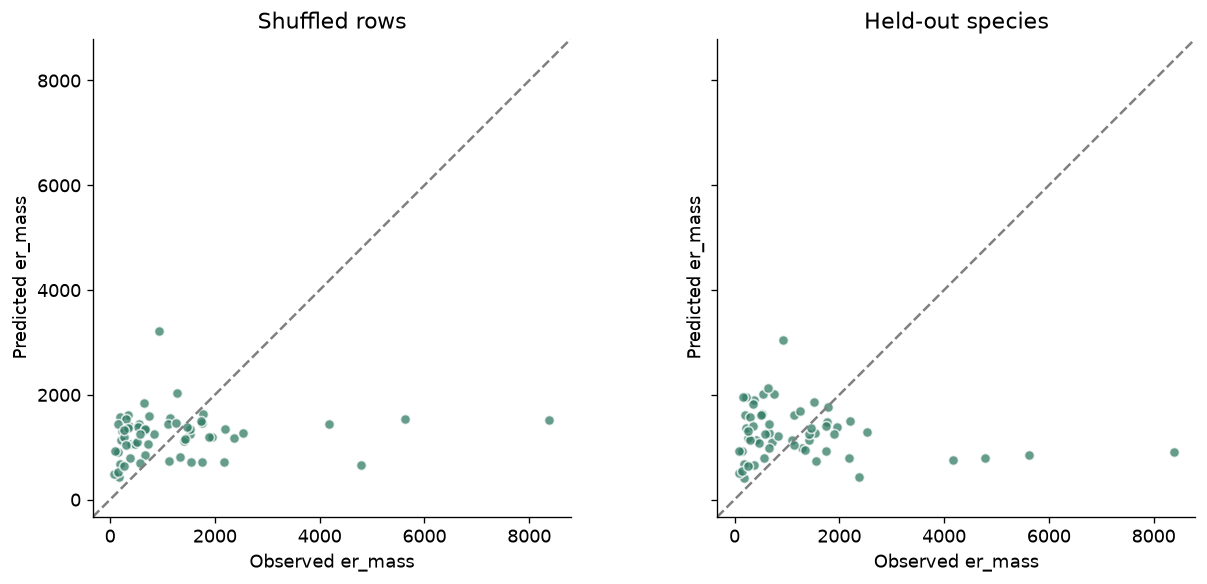

design
Held-out species    0
Shuffled rows       0
Name: negative_prediction, dtype: int64

In [12]:
ridge_oof = oof.loc[oof.model == "Scaled ridge"]
lo = min(ridge_oof.observed.min(), ridge_oof.predicted.min())
hi = max(ridge_oof.observed.max(), ridge_oof.predicted.max())
pad = (hi - lo) * .05
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (design, table) in zip(axes, ridge_oof.groupby("design", sort=False)):
    ax.scatter(table.observed, table.predicted, color="#327b65", alpha=.75, edgecolor="white")
    ax.plot([lo-pad, hi+pad], [lo-pad, hi+pad], "--", color="gray")
    ax.set(title=design, xlabel="Observed er_mass", ylabel="Predicted er_mass",
           xlim=(lo-pad, hi+pad), ylim=(lo-pad, hi+pad))
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()
display(ridge_oof.assign(negative_prediction=ridge_oof.predicted < 0).groupby("design").negative_prediction.sum())

## Part 8 — Which species are hard to predict?

For leave-one-species-out evaluation, each species' error is based on a different training fit. Compare ridge with its baseline on the same held-out observations. Positive improvement below means ridge has smaller MAE than the median baseline.

There are few observations per species. These are descriptive errors, not reliable species rankings or confidence intervals. Shared plots, evolutionary relationships, and growing conditions can limit independence even after separating species.

model,Median baseline,Scaled ridge,ridge_improvement,n_test
species,,,,
A.saccharum,677.583,596.221,81.362,5
A.triloba,525.452,1246.939,-721.487,4
C.ovata,627.326,763.773,-136.446,5
C.pisifera,571.393,782.127,-210.733,7
J.chinensis,1003.973,1433.793,-429.820,6
L.gmelinii,3169.706,2989.013,180.693,6
P.abies,870.351,434.808,435.543,6
P.occidentalis,723.974,635.614,88.360,5
Q.bicolor,434.712,390.181,44.530,6


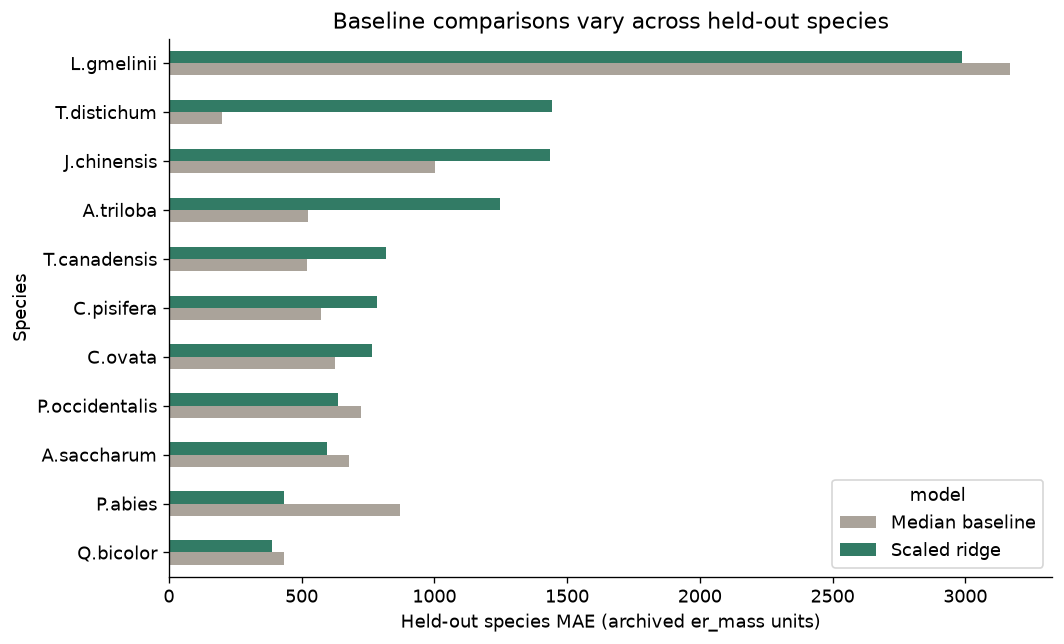

In [13]:
grouped = oof.loc[oof.design == "Held-out species"]
species_errors = grouped.groupby(["species", "model"]).absolute_error.mean().unstack("model")
species_errors["ridge_improvement"] = species_errors["Median baseline"] - species_errors["Scaled ridge"]
species_errors["n_test"] = groups.value_counts()
display(species_errors.round(3))
fig, ax = plt.subplots(figsize=(9, 5.5))
species_errors[["Median baseline", "Scaled ridge"]].sort_values("Scaled ridge").plot.barh(
    ax=ax, color=["#aaa39a", "#327b65"])
ax.set(xlabel="Held-out species MAE (archived er_mass units)", ylabel="Species",
       title="Baseline comparisons vary across held-out species")
fig.tight_layout()
plt.show()

## Part 9 — What conclusions are justified?

Use the measured results rather than assuming grouped evaluation must have larger errors. The split changes the prediction question; a numerical gap also reflects the particular sample, fold composition, training sizes, and model.

This fixed ridge model is deliberately simple. Comparing a few evaluated procedures does not establish that one is best for all new species. Cross-validation reuses overlapping training sets. Its folds are not independent replications, so a standard deviation across folds is not automatically a confidence interval. There is no untouched external dataset here.

The next cell calculates concrete statements from the results. Read them alongside the per-species table and the target distribution. A failure to outperform a baseline is a useful result, not a reason to hide the evaluation.

In [14]:
metrics = summary.set_index(["design", "model"])
random_mae = metrics.loc[("Shuffled rows", "Scaled ridge"), "pooled_MAE"]
new_species_mae = metrics.loc[("Held-out species", "Scaled ridge"), "pooled_MAE"]
grouped_baseline_mae = metrics.loc[("Held-out species", "Median baseline"), "pooled_MAE"]
print(f"Ridge shuffled-row MAE: {random_mae:.2f}")
print(f"Ridge held-out-species MAE: {new_species_mae:.2f}")
print(f"Change (held-out species minus shuffled rows): {new_species_mae-random_mae:+.2f}")
print(f"Held-out-species median-baseline MAE: {grouped_baseline_mae:.2f}")
print(f"Ridge improves on baseline for {(species_errors.ridge_improvement > 0).sum()} of {len(species_errors)} species.")

Ridge shuffled-row MAE: 952.87
Ridge held-out-species MAE: 1043.40
Change (held-out species minus shuffled rows): +90.53
Held-out-species median-baseline MAE: 884.00
Ridge improves on baseline for 5 of 11 species.


### Worked interpretation of this release

With the fixed settings above, ridge's pooled MAE increases from **952.87** under shuffled-row validation to **1,043.40** when species are held out. The held-out-species median baseline has a smaller MAE of **884.00**. Ridge improves on that baseline for only **5 of 11 species**. Errors are in archived `er_mass` units.

Thus these results do not support adopting this ridge model for unseen species. The median baseline also has lower MAE under shuffled rows, although ridge has lower RMSE under that design. That difference illustrates why the metric and baseline need to match the question. The highest observed values are substantially underpredicted in the scatter plots. Neither selecting the most favorable metric nor removing those observations after evaluation would establish generalization.

This comparison demonstrates the evaluation procedure, not a universal rule that grouped MAE must increase or that root traits cannot predict exudation. A different model may be worth studying, but it needs its own properly separated evaluation.

## Part 10 — Save predictions and the evaluation design

Preserve each prediction's source row, species, fold, and model. Save the split audit and exact train/test row assignments, not just an average score. The source workbook is unchanged.

In [15]:
oof.to_csv(out_dir / "out_of_fold_predictions.csv", index=True)
summary.to_csv(out_dir / "evaluation_summary.csv", index=False)
species_errors.to_csv(out_dir / "held_out_species_errors.csv", index=True)
pd.concat(split_audits, names=["design", "row"]).to_csv(out_dir / "split_audit.csv")
pd.DataFrame({"retained": keep}, index=df.index).to_csv(out_dir / "row_audit.csv")
assignments = {name: [{"fold": fold, "train_source_rows": X.index[train].tolist(),
                       "test_source_rows": X.index[test].tolist()}
                      for fold, (train, test) in enumerate(splits, start=1)]
               for name, splits in split_sets.items()}
(out_dir / "fold_assignments.json").write_text(json.dumps(assignments, indent=2))
provenance = {"dataset_doi": DATASET_DOI, "source_sha256": source_hash,
    "source_release": "2026-05-06", "features": features, "target": target,
    "groups": "species", "target_scale": "Original archived values, no transform or clipping",
    "n_observations": len(X), "n_species": int(n_species), "random_seed": SEED,
    "random_folds": int(n_species), "grouped_design": "Leave one species out",
    "ridge_alpha": ALPHA, "ridge_solver": "svd", "tuning": "None; fixed teaching setting",
    "scaling": "StandardScaler fitted inside each training fold",
    "baseline": "Training median", "python": platform.python_version(),
    "packages": {package: version(package) for package in
                 ["pandas", "numpy", "scikit-learn", "matplotlib", "openpyxl"]}}
(out_dir / "analysis_provenance.json").write_text(json.dumps(provenance, indent=2))
saved = pd.read_csv(out_dir / "out_of_fold_predictions.csv")
np.testing.assert_allclose(saved.predicted, oof.predicted, atol=1e-9)
assert len(saved) == len(oof)
print("Saved predictions, summaries, fold assignments, audits, and provenance.")

Saved predictions, summaries, fold assignments, audits, and provenance.


## Part 11 — Exercises

### Exercise 1: Identify the deployment question

For each case, describe an appropriate split and the information needed to implement it: a new tree from a previously observed species, a new species, and a new research site. Explain why holding out species cannot demonstrate transfer to new sites in this single-site dataset.

### Exercise 2: Audit species overlap

Choose one shuffled-row fold. List the species shared between training and testing. Compare with one grouped fold. Explain why unique tree IDs alone do not ensure independence across species.

### Exercise 3: Change the baseline

Evaluate `DummyRegressor(strategy="mean")` on the same saved splits. Compare MAE and RMSE with the median baseline. Which loss does the mean minimize on training data, and which does the median minimize?

### Exercise 4: Random-split sensitivity

Repeat shuffled-row evaluation for five seeds, keeping alpha fixed. Show the range of pooled MAEs. Do not choose the most favorable seed as the headline result. Explain why repeated splits are not five new datasets.

### Exercise 5: Predict with PCA inside the pipeline

Insert `PCA(n_components=2, svd_solver="full")` between `StandardScaler()` and `Ridge()`. Evaluate on the same species-held-out splits. Use the training-fold pipeline, not the earlier notebook's full-data scores. State why high explained predictor variance need not imply better target prediction.

### Exercise 6: Write a community-facing interpretation

Write 100–150 words giving the target, data affiliation, sample size, split design, ridge and baseline MAE, and one limitation. Avoid describing the model as reliable for all trees or claiming traits cause exudation differences.

### Challenge: Nested group-aware tuning

Within each outer held-out-species fold, use an inner `GroupKFold` and `GridSearchCV` to choose among a small alpha grid. Pass only the outer-training species as inner groups. Refit the selected pipeline on the outer-training data, then predict the outer-held-out species exactly once. Compare nested out-of-fold errors with the fixed-alpha example. Never pick alpha from the outer test errors.

## Part 12 — Reflection and discussion

1. Why can a model recognize species-related patterns without receiving species names?
2. Why does scaling before cross-validation expose information from the test distribution?
3. Why might row-weighted MAE and equally weighted species MAE disagree?
4. What would a negative pooled out-of-fold R² tell you, and what would it not tell you?
5. What additional data would support a claim about new locations or new growing conditions?
6. If grouped validation performs worse than the baseline, how would you communicate that constructively?

### MCDC Connection: Matching Evidence to Intended Use

The choice of evaluation design is part of defining a responsible data product. A community partner needs to know which future observations resemble the evaluation data. An error estimate for familiar species should not silently become a promise about unseen species. Reporting a baseline, fold design, and limitations makes the analysis more useful even when prediction is weak.

## Source notes and limitations

The 60-row, 11-species workbook is Morton-affiliated research data, not the original MCDC inventory. The sample is small and selected. Species-held-out validation does not remove every biological or experimental dependency. Physical units require consulting the source documentation. This fixed original-scale ridge model omits the paper's more extensive modeling and is not an attempted reproduction. Model revisions based on these results would require a fresh or nested evaluation for an unbiased performance claim.

## Acknowledgment and further reading

This lesson follows the context, worked-example, validation, exercise, and reflection structure of the summer 2026 TIF and Morton PCA lessons.

- [Oh and colleagues' dataset](https://doi.org/10.5061/dryad.vmcvdnd78)
- [Related article](https://doi.org/10.1111/1365-2435.70363)
- [MCDC Morton project](https://sites.northwestern.edu/mcdc/data-cleaning-morton-arboretum-tree-species/)
- [Scikit-learn cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Ridge regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
- [Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)